# Assignment 5 – Convolutional Neural Network (CNN)

**Team members:** Sandra Paola Aguilar Rangel (2178036) Andrea Elizondo Ocañas (2096175), Nelly Renata Garzon Medina (2114761), Erick Alejandro Cantu Plascencia (2105789)

**Class schedule:** Tuesday N4  




**Objective:** To train and evaluate a convolutional neural network capable of classifying handwritten digit images from the MNIST dataset.

**Instructions:** Run all cells in order, from the first cell to the last one.


## 1. Importing the libraries

TensorFlow/Keras is used to build the neural network, Matplotlib to display images and plots, and NumPy to work with numerical arrays.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: False


## 2. Loading the dataset

The MNIST dataset contains 60,000 training images and 10,000 test images. Each image represents a handwritten digit from 0 to 9 and has a resolution of 28 × 28 pixels.


In [2]:
(train_data, train_labels), (test_data, test_labels) = keras.datasets.mnist.load_data()

print("Training images shape:", train_data.shape)
print("Training labels shape:", train_labels.shape)
print("Test images shape:", test_data.shape)
print("Test labels shape:", test_labels.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


## 3. Data preprocessing

Pixel values are normalized from the range 0–255 to the range 0–1. A channel dimension is then added because the CNN expects images with height, width, and channels. MNIST images are grayscale, so they have one channel.


In [3]:
train_data = train_data.astype("float32") / 255.0
test_data = test_data.astype("float32") / 255.0

# Add one channel to each grayscale image.
train_data = np.expand_dims(train_data, axis=-1)
test_data = np.expand_dims(test_data, axis=-1)

print("New training data shape:", train_data.shape)
print("New test data shape:", test_data.shape)


New training data shape: (60000, 28, 28, 1)
New test data shape: (10000, 28, 28, 1)


### Visualizing sample images

The following cell displays nine images from the training dataset together with their true labels.


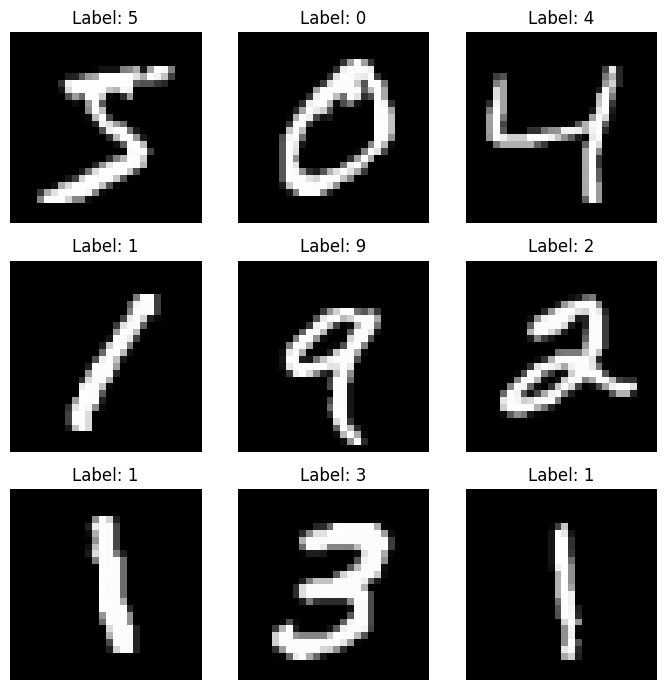

In [4]:
plt.figure(figsize=(7, 7))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(train_data[i].squeeze(), cmap="gray")
    plt.title(f"Label: {train_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 4. Model selection and training

A sequential CNN is proposed. It contains two convolutional layers, two max-pooling layers to reduce spatial dimensions, a dropout layer to help reduce overfitting, a dense layer, and an output layer with 10 neurons.

- **Output activation function:** Softmax, to produce probabilities for the ten digit classes.
- **Loss function:** Sparse categorical crossentropy, because the labels are integer values from 0 to 9.
- **Optimizer:** Adam.
- **Evaluation metric:** Accuracy.


In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dropout(0.25),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train for five epochs and use 10% of the training data for validation.
history = model.fit(
    train_data,
    train_labels,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9298 - loss: 0.2353 - val_accuracy: 0.9832 - val_loss: 0.0600
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 50s 120ms/step - accuracy: 0.9785 - loss: 0.0698 - val_accuracy: 0.9863 - val_loss: 0.0448
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 76s 105ms/step - accuracy: 0.9840 - loss: 0.0505 - val_accuracy: 0.9907 - val_loss: 0.0367
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.9875 - loss: 0.0395 - val_accuracy: 0.9898 - val_loss: 0.0353
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.9895 - loss: 0.0329 - val_accuracy: 0.9905 - val_loss: 0.0349


### Training performance plots

The following plots show accuracy and loss during training and validation.


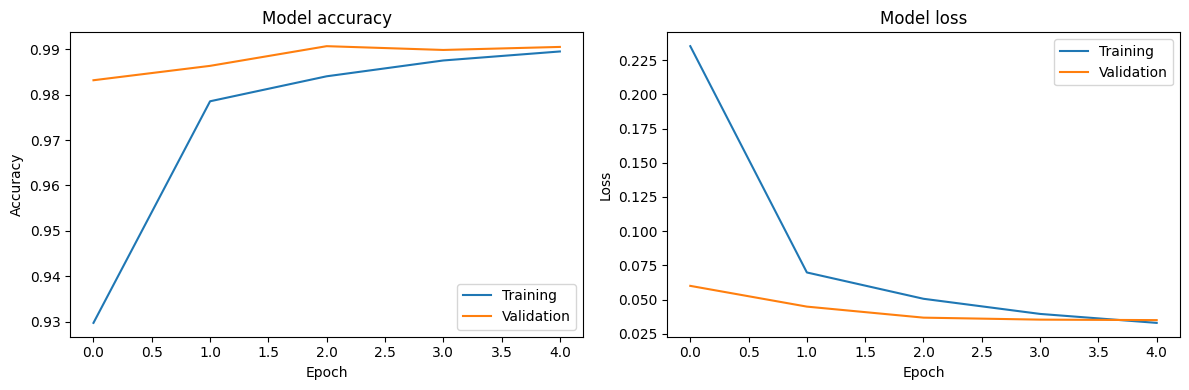

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


## 5. Model testing and evaluation

The model is evaluated with the test dataset, which was not used to update the model weights during training. The test accuracy is also displayed as a percentage.


In [8]:
test_loss, test_accuracy = model.evaluate(test_data, test_labels, verbose=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")


Test loss: 0.0292
Test accuracy: 98.99%


## 6. Making five predictions

Five images are selected from the test dataset. For each image, the network prediction is compared with the true label. If both values match, the prediction is classified as correct.


Image 1: prediction = 7, actual value = 7, result = Correct
Image 2: prediction = 2, actual value = 2, result = Correct
Image 3: prediction = 1, actual value = 1, result = Correct
Image 4: prediction = 0, actual value = 0, result = Correct
Image 5: prediction = 4, actual value = 4, result = Correct


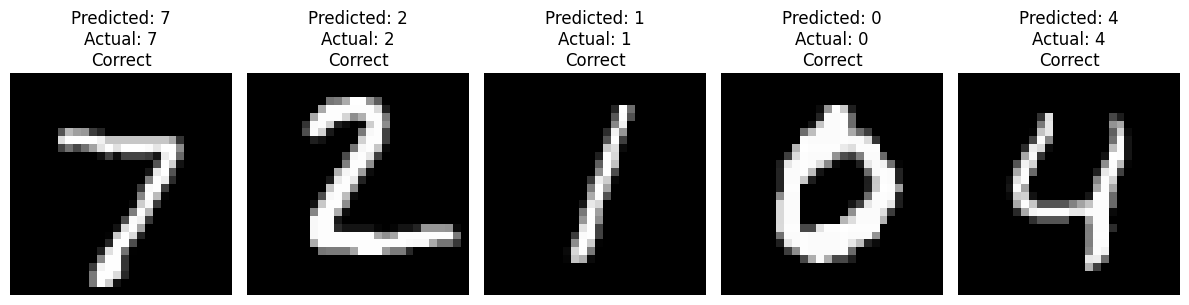

In [9]:
probabilities = model.predict(test_data[:5], verbose=0)
predictions = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 3))
for i in range(5):
    predicted = int(predictions[i])
    actual = int(test_labels[i])
    result = "Correct" if predicted == actual else "Incorrect"

    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].squeeze(), cmap="gray")
    plt.title(f"Predicted: {predicted}\nActual: {actual}\n{result}")
    plt.axis("off")

    print(f"Image {i + 1}: prediction = {predicted}, actual value = {actual}, result = {result}")

plt.tight_layout()
plt.show()


## 7. Saving the trained model (optional)

This cell saves the trained model in Keras format in the current Colab session. The file can be downloaded from the Files panel if a separate copy is needed.


In [10]:
model.save("model_CNN_MNIST.keras")
print("Model saved as model_CNN_MNIST.keras")


Model saved as model_CNN_MNIST.keras


## 8. Notebook conclusion

The convolutional neural network was trained using the MNIST dataset to classify handwritten digits. The model was evaluated with test images that were not used to update its weights during training. The five individual predictions provide an additional visual check by comparing each predicted digit with its true label.

After running the notebook, report the test accuracy and test loss displayed in Section 5, and compare the five predictions shown in Section 6.
